# 01 基线回测（无止损止盈）+ 买入持有基准
IS = 2012-08~2019-12，OOS = 2020-01~今。基线没有参数，所以可以直接同时看 IS/OOS。

In [1]:
%run 00_engine.ipynb


数据区间: 2011-10-03 ~ 2026-10-07 | 信号分布: {'TQQQ': 2904, 'TECL': 249, 'TECS': 203, 'BSV': 150, 'UVXY': 133, 'SPXL': 17}


In [2]:
rows=[]
for name,cb,ub in [('无成本',0,0),('5/10bps',5,10)]:
    eq,tr=backtest(O,H,L,C,tg,None,None,True,cb,ub)
    for lab,a,b in [('IS',IS_START,IS_END),('OOS',OOS_START,None),('OOS剔除2020','2021-01-01',None)]:
        rows.append({'方案':'策略 '+name,'区间':lab,**fmt(metrics(eq,a=a,b=b))})
for t in ['SPY','TQQQ']:
    e=C[t].loc[IS_START:]
    for lab,a,b in [('IS',IS_START,IS_END),('OOS',OOS_START,None),('OOS剔除2020','2021-01-01',None)]:
        rows.append({'方案':'买入持有 '+t,'区间':lab,**fmt(metrics(e,a=a,b=b))})
pd.DataFrame(rows)

,方案,区间,CAGR,Vol,Sharpe,Sortino,MDD,Calmar
0,策略 无成本,IS,0.492,0.497,1.052,1.593,-0.726,0.678
1,策略 无成本,OOS,1.666,0.730,1.706,2.764,-0.506,3.290
2,策略 无成本,OOS剔除2020,0.994,0.656,1.378,2.164,-0.506,1.963
3,策略 5/10bps,IS,0.446,0.497,0.989,1.490,-0.738,0.604
4,策略 5/10bps,OOS,1.584,0.730,1.663,2.686,-0.508,3.117
5,策略 5/10bps,OOS剔除2020,0.939,0.656,1.335,2.091,-0.508,1.847
6,买入持有 SPY,IS,0.144,0.128,1.124,1.586,-0.193,0.746
7,买入持有 SPY,OOS,0.154,0.200,0.817,1.158,-0.337,0.456
8,买入持有 SPY,OOS剔除2020,0.154,0.166,0.945,1.378,-0.245,0.627
9,买入持有 TQQQ,IS,0.503,0.474,1.101,1.554,-0.581,0.867


分年收益:


,return
2013-12-31,1.434
2014-12-31,0.701
2015-12-31,-0.241
2016-12-31,0.700
2017-12-31,1.391
2018-12-31,-0.515
2019-12-31,1.561
2020-12-31,13.934
2021-12-31,1.559
2022-12-31,0.200


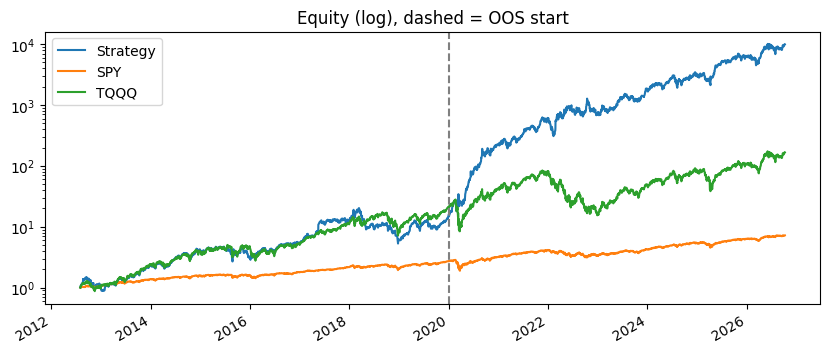

In [3]:
eq,tr=backtest(O,H,L,C,tg,None,None,True,5,10)
print('分年收益:'); display((eq.resample('YE').last().pct_change()).round(3).dropna().to_frame('return'))
fig,ax=plt.subplots(figsize=(10,4))
(eq/eq.iloc[0]).plot(ax=ax,logy=True,label='Strategy')
for t in ['SPY','TQQQ']:
    (C[t].loc[eq.index[0]:]/C[t].loc[eq.index[0]:].iloc[0]).plot(ax=ax,logy=True,label=t)
ax.axvline(pd.Timestamp(OOS_START),color='gray',ls='--'); ax.legend(); ax.set_title('Equity (log), dashed = OOS start'); plt.show()